# Hierarchical clustering — library lab

Hands-on companion to [README §4](../../README.md#4-hierarchical-agglomerative-clustering). It uses the ready-made implementations in **scikit-learn** and **SciPy**;
the sister notebook [`hierarchical_from_scratch.ipynb`](hierarchical_from_scratch.ipynb) rebuilds the same algorithm in NumPy.

Part of the [clustering labs](../README.md), one folder per method: [k-means](../01-kmeans/kmeans_lab.ipynb) · [hierarchical](../02-hierarchical/hierarchical_lab.ipynb) · [DBSCAN](../03-dbscan/dbscan_lab.ipynb) · [OPTICS / HDBSCAN](../04-optics-hdbscan/optics_hdbscan_lab.ipynb) · [in practice](../05-in-practice/in_practice_lab.ipynb).

**How to use it**

1. Run the first code cell (imports and helpers). After that, run the labs in order (`Shift + Enter` cell by cell, or
   **Run All**). Labs only reuse things from earlier cells, so top-to-bottom always works.
2. Read the "How to read this" box *after* looking at the output: try to guess first.
3. Change the numbers marked `# <- try changing this` and re-run to build intuition.

**One score used everywhere:** the data in these labs comes with the "true" groups it was generated from, which a real
clustering problem doesn't have. We use them only to *grade* a result with the **adjusted Rand index (ARI)**: 1 = the
clusters match the true groups exactly, 0 = no better than random labels (it can dip slightly below 0).

| Lab | What it shows |
|---|---|
| [5](#lab-5) | reading and cutting a dendrogram |
| [6](#lab-6) | what the linkage changes |
| [Summary](#summary) | one line per lab |

Everything runs offline: the data is generated in the notebook or ships with scikit-learn.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import cophenet, dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist

from sklearn.cluster import AgglomerativeClustering
from sklearn.datasets import load_iris, make_blobs, make_circles, make_moons
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler


np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
SEED = 0


def plot_clusters(ax, X, labels, title, centers=None):
    """Scatter 2-D points coloured by cluster label. Label -1 (noise) is drawn as small grey crosses,
    optional `centers` as black stars."""
    labels = np.asarray(labels)
    noise = labels == -1
    ax.scatter(X[~noise, 0], X[~noise, 1], c=labels[~noise] % 10, cmap="tab10", vmin=0, vmax=9, s=12)
    if noise.any():
        ax.scatter(X[noise, 0], X[noise, 1], c="gray", marker="x", s=14, label="noise")
    if centers is not None:
        ax.scatter(centers[:, 0], centers[:, 1], c="black", marker="*", s=200, label="centroid")
    ax.set_title(title, fontsize=10); ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")


def make_shapes(n=500, seed=SEED):
    """The six 2-D test sets used throughout (as in scikit-learn's cluster-comparison gallery).
    Returns {name: (X, true_labels, number_of_true_clusters)}."""
    X_blob, y_blob = make_blobs(n, centers=3, random_state=seed + 170)
    X_aniso = X_blob @ np.array([[0.6, -0.6], [-0.4, 0.8]])             # stretch and shear the same blobs
    X_var, y_var = make_blobs(n, centers=3, cluster_std=[0.5, 1.5, 3.0], random_state=seed + 170)
    X_size, y_size = make_blobs([300, 150, 25], centers=[[-4, 0], [0, 0], [3.5, 0]], cluster_std=1.0,
                                random_state=seed)
    X_moon, y_moon = make_moons(n, noise=0.06, random_state=seed)
    X_circ, y_circ = make_circles(n, factor=0.45, noise=0.05, random_state=seed)
    return {"round blobs": (X_blob, y_blob, 3), "stretched blobs": (X_aniso, y_blob, 3),
            "unequal spreads": (X_var, y_var, 3), "unequal sizes": (X_size, y_size, 3),
            "moons": (X_moon, y_moon, 2), "circles": (X_circ, y_circ, 2)}


shapes = make_shapes()

<a id="lab-5"></a>

## Lab 5 · Reading and cutting a dendrogram

**Goal:** agglomerative clustering (README §4) starts with every point as its own cluster and repeatedly **merges the
two closest clusters** until one is left. The result is a tree, the **dendrogram**, and any number of clusters can be
read off by cutting it. Here: 12 points (three groups and a loner), **average linkage** (cluster distance = average of
all point-to-point distances between the two clusters).

first 5 merges (cluster ids >= 12 are clusters made by earlier merges):
   i     j   distance  size
   1     3     0.361     2
   7    10     0.424     2
   4     6     0.447     2
   2    12     0.505     3
   9    13     0.539     3
last 3 merges (the big ones):
  11    18     2.177     4
  19    20     4.825     8
  17    21     6.360    12

cut at height 3.0: 3 clusters [1 1 1 1 3 3 3 2 2 2 2 3]
ask for 3 clusters  : [1 1 1 1 3 3 3 2 2 2 2 3]
scikit-learn, 3 clusters, same linkage: [2 2 2 2 1 1 1 3 3 3 3 1]  -> same partition: True


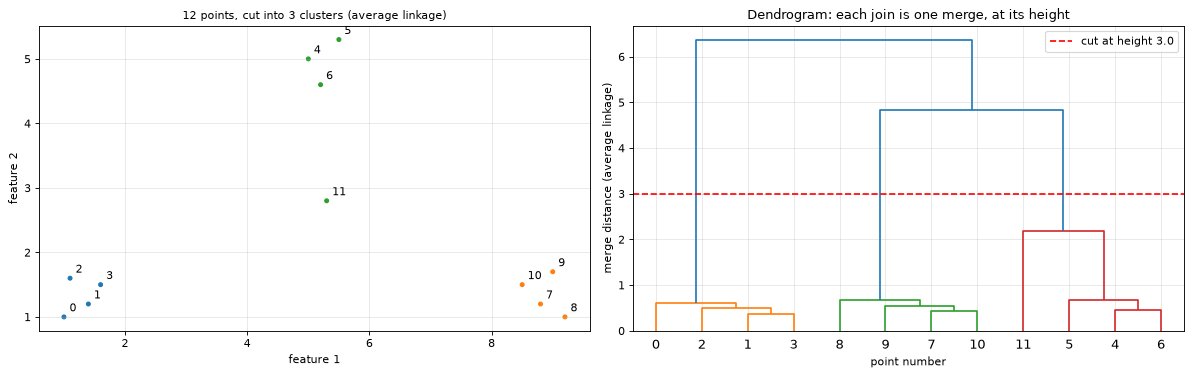

In [2]:
X5 = np.array([[1.0, 1.0], [1.4, 1.2], [1.1, 1.6], [1.6, 1.5],          # group A (points 0-3)
               [5.0, 5.0], [5.5, 5.3], [5.2, 4.6],                      # group B (points 4-6)
               [8.8, 1.2], [9.2, 1.0], [9.0, 1.7], [8.5, 1.5],          # group C (points 7-10)
               [5.3, 2.8]])                                             # a loner between B and C (point 11)
Z = linkage(X5, method="average")                                       # rows: [cluster i, cluster j, distance, size]
print("first 5 merges (cluster ids >= 12 are clusters made by earlier merges):")
print("   i     j   distance  size")
for i, j, d, size in Z[:5]:
    print(f"{int(i):4d}  {int(j):4d}   {d:7.3f}  {int(size):4d}")
print("last 3 merges (the big ones):")
for i, j, d, size in Z[-3:]:
    print(f"{int(i):4d}  {int(j):4d}   {d:7.3f}  {int(size):4d}")

cut_height = 3.0                                                         # <- try another height
by_height = fcluster(Z, t=cut_height, criterion="distance")             # cut the tree at a height
by_count = fcluster(Z, t=3, criterion="maxclust")                       # or ask for a number of clusters
sk = AgglomerativeClustering(n_clusters=3, linkage="average").fit_predict(X5)
print(f"\ncut at height {cut_height}: {len(set(by_height))} clusters {by_height}")
print(f"ask for 3 clusters  : {by_count}")
print(f"scikit-learn, 3 clusters, same linkage: {sk + 1}  -> same partition: {adjusted_rand_score(by_count, sk) == 1.0}")

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
plot_clusters(axes[0], X5, by_count - 1, "12 points, cut into 3 clusters (average linkage)")
for i, (a, b) in enumerate(X5):
    axes[0].annotate(str(i), (a, b), textcoords="offset points", xytext=(5, 5))
dendrogram(Z, ax=axes[1], color_threshold=cut_height)
axes[1].axhline(cut_height, color="red", ls="--", label=f"cut at height {cut_height}")
axes[1].set_xlabel("point number"); axes[1].set_ylabel("merge distance (average linkage)")
axes[1].set_title("Dendrogram: each join is one merge, at its height"); axes[1].legend()
plt.tight_layout(); plt.show()

> **How to read this**
> * The **linkage matrix** `Z` has one row per merge: the two clusters joined, the distance at which they were joined,
>   and the new cluster's size. Point ids are 0–11; the cluster made by merge number m gets id 12 + m. The first merge
>   joins points 1 and 3 (distance **0.361**), the third joins 4 and 6, and row 4 merges point 2 into cluster 12
>   (the pair 1 + 3).
> * In the dendrogram each ∩ is one merge, drawn at its distance. Short joins at the bottom are the tight groups; the
>   loner (point 11) joins group B late, at **2.177**; the last two merges happen at **4.825** and **6.360**.
> * **Cutting** at height 3.0 (red line) keeps every merge below it: **3 clusters**, `[1 1 1 1 3 3 3 2 2 2 2 3]`.
>   Asking for 3 clusters gives the same answer. scikit-learn's `AgglomerativeClustering` finds the same partition;
>   only the cluster numbers differ.
> * A big vertical gap between consecutive merge heights (here 2.177 → 4.825) is the natural place to cut.

<a id="lab-6"></a>

## Lab 6 · What the linkage changes

**Goal:** the **linkage** is the rule for the distance between two *clusters*, and it decides the shapes the method can
find (README §4.2). Compare the four common ones on moons, unequal spreads, and two blobs joined by a thin bridge of
points, then check how faithfully each tree preserves the real distances on iris.

<details>
<summary><b>The four linkages, in formulas (click to expand)</b></summary>

For clusters $A$ and $B$ with sizes $|A|, |B|$ and point distances $d(a, b)$:

| Linkage | Distance between clusters | Tends to |
|---|---|---|
| **single** | $\min_{a \in A, b \in B} d(a, b)$ (closest pair) | follow chains: finds any shape, but one bridge of points merges two clusters |
| **complete** | $\max_{a, b} d(a, b)$ (farthest pair) | compact clusters of similar diameter |
| **average** | $\frac{1}{\lvert A\rvert \lvert B\rvert} \sum_{a, b} d(a, b)$ | in between |
| **ward** | the increase in total within-cluster sum of squares caused by merging $A$ and $B$: $\frac{\lvert A\rvert \lvert B\rvert}{\lvert A\rvert + \lvert B\rvert} \lVert \mu_A - \mu_B \rVert^2$ | round clusters of similar size, like k-means |

After every merge the distances from the new cluster to all others are updated with one formula (Lance–Williams), so
the point distances never have to be recomputed; the [from-scratch notebook](hierarchical_from_scratch.ipynb) implements it.

The **cophenetic distance** between two points is the height at which they first end up in the same cluster. The
**cophenetic correlation** is the correlation between those heights and the real distances: 1 = the tree is a perfect
summary of the distances.

</details>

ARI (1 = matches the true groups)          single  complete   average      ward
  moons                                     1.00      0.45      0.45      0.56
  unequal spreads                           0.00      0.59      0.57      0.61
  2 blobs + a thin bridge                  -0.00      0.99      0.95      0.95

iris (standardised): cophenetic correlation = how faithfully the tree's merge heights keep the real distances
  single   cophenetic correlation 0.830   ARI with 3 clusters 0.56
  complete cophenetic correlation 0.751   ARI with 3 clusters 0.57
  average  cophenetic correlation 0.854   ARI with 3 clusters 0.56
  ward     cophenetic correlation 0.823   ARI with 3 clusters 0.62


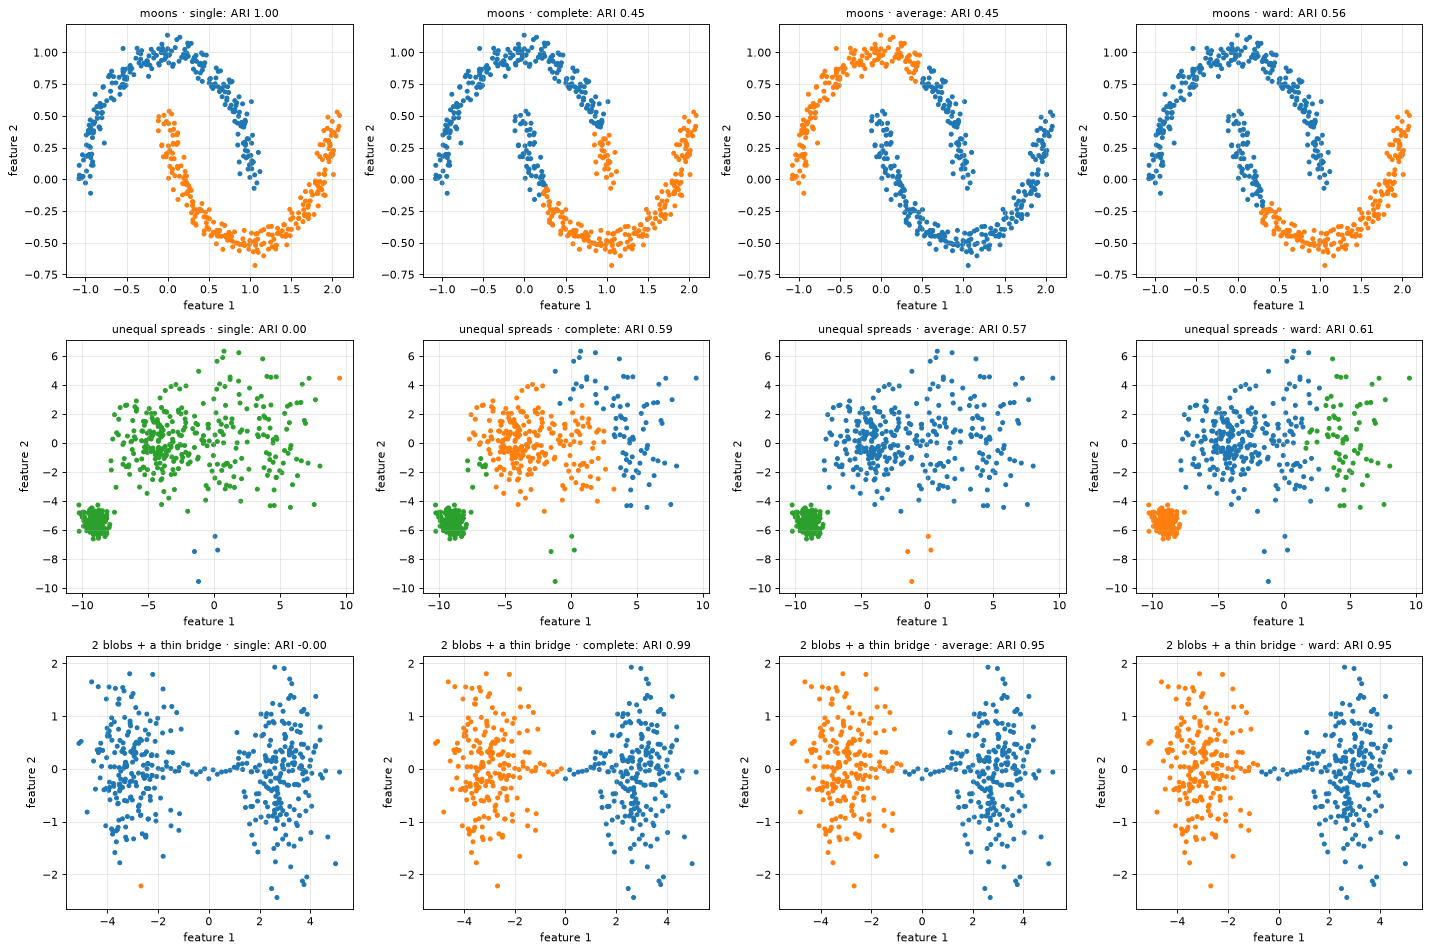

In [3]:
X_bridge, y_bridge = make_blobs(400, centers=[[-3, 0], [3, 0]], cluster_std=0.8, random_state=SEED)
bridge = np.column_stack([np.linspace(-2, 2, 25), np.random.default_rng(SEED).normal(0, 0.08, 25)])
X_bridge = np.vstack([X_bridge, bridge]); y_bridge = np.append(y_bridge, (bridge[:, 0] > 0).astype(int))
link_sets = {"moons": shapes["moons"][:2], "unequal spreads": shapes["unequal spreads"][:2],
             "2 blobs + a thin bridge": (X_bridge, y_bridge)}
linkages = ["single", "complete", "average", "ward"]

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
print("ARI (1 = matches the true groups)        " + "  ".join(f"{m:>8s}" for m in linkages))
for row, (name, (X, y)) in enumerate(link_sets.items()):
    k = len(np.unique(y)); aris = []
    for col, method in enumerate(linkages):
        labels = AgglomerativeClustering(n_clusters=k, linkage=method).fit_predict(X)
        aris.append(adjusted_rand_score(y, labels))
        plot_clusters(axes[row, col], X, labels, f"{name} · {method}: ARI {aris[-1]:.2f}")
    print(f"  {name:38s}" + "  ".join(f"{a:8.2f}" for a in aris))

iris_X = StandardScaler().fit_transform(load_iris().data)
print("\niris (standardised): cophenetic correlation = how faithfully the tree's merge heights keep the real distances")
for method in linkages:
    Zi = linkage(iris_X, method=method)
    c, _ = cophenet(Zi, pdist(iris_X))
    ari = adjusted_rand_score(load_iris().target, fcluster(Zi, 3, criterion="maxclust"))
    print(f"  {method:8s} cophenetic correlation {c:.3f}   ARI with 3 clusters {ari:.2f}")
plt.tight_layout(); plt.show()

> **How to read this**
> * **Moons:** only **single** linkage gets them (ARI **1.00**); complete 0.45, average 0.45, ward 0.56. Following the
>   chain of nearest neighbours traces any shape.
> * **Unequal spreads:** single linkage scores **0.00**: one giant cluster of 495 points, and the other two "clusters"
>   are 4 and 1 stray points from the wide cluster's edge. Every gap inside the data is bridged by some chain of near
>   neighbours. Ward does best (0.61).
> * **Two blobs + a thin bridge:** single linkage again **0.00**: the bridge chains the blobs into one cluster of 424
>   points plus 1 leftover point. Complete **0.99**, average and ward 0.95.
> * **Iris:** average linkage keeps the real distances best (cophenetic correlation **0.854**), but ward gives the best
>   3-cluster split (ARI **0.62**). A tree that summarises distances well is not necessarily the best cut.
> * So: single linkage for odd shapes with clean gaps; ward (or complete) for compact clusters and noisy data.

---

<a id="summary"></a>

# Summary — what each lab showed

| Lab | Claim from the README | Verdict |
|---|---|---|
| [5](#lab-5) | A dendrogram holds every clustering; cut it at a height or a count | ✔ same 3 clusters both ways; scikit-learn agrees |
| [6](#lab-6) | The linkage decides the shapes found | ✔ single: moons 1.00 but a bridge breaks it (0.00); complete 0.99 |